# Project 5: Sensor Time-Series Anomaly Detection
Notebook membaca CSV hasil (`results/`), tidak menghitung ulang model. Urutan mengikuti 12 pertanyaan pada Design Project.

Catatan: hanya 4 kejadian berlabel (2 latih, 2 uji), jadi semua kesimpulan indikatif.

In [1]:
import pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
R1, R2, R3 = "../1-data-preparation/", "../2-analysis/", "./"
def rd(p, **k): return pd.read_csv(p, **k)

## Q1. Pola suhu harian dan mingguan, rentang suhu normal

                                      ukuran      nilai
            suhu rata-rata (di luar jendela)  88.359144
                              simpangan baku   9.786469
                                      median  89.932751
                                 persentil 5  67.373731
                                persentil 95 100.962712
                rata-rata - 2 simpangan baku  68.786207
                rata-rata + 2 simpangan baku 107.932081
selisih rata-rata jam tertinggi dan terendah   3.678282
 varians dijelaskan jam dalam sehari (eta^2)   0.013238
varians dijelaskan hari dalam minggu (eta^2)   0.038359
            rata-rata dalam jendela berlabel  64.016597
                       rata-rata harian: min  34.498251
                      rata-rata harian: maks 102.373107


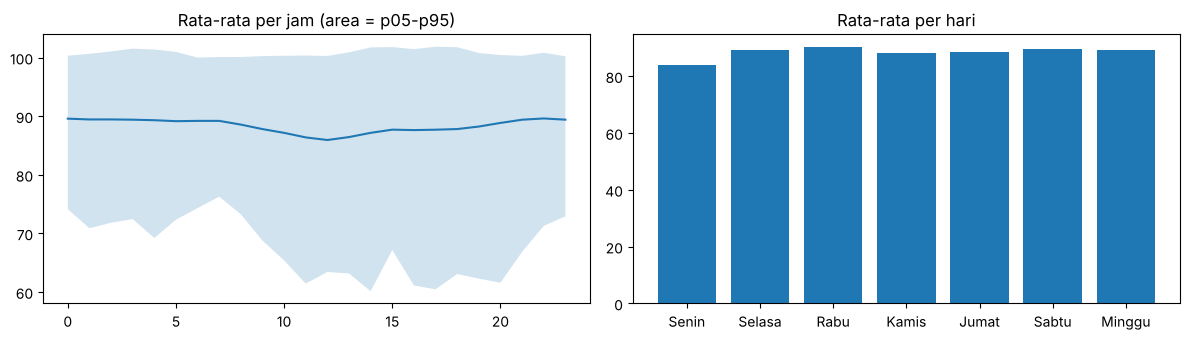

In [2]:
print(rd(R1+"profile_summary.csv").to_string(index=False))
h, d = rd(R1+"profile_hour.csv"), rd(R1+"profile_dow.csv")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(h.hour, h["mean"]); ax[0].fill_between(h.hour, h.p05, h.p95, alpha=.2); ax[0].set_title("Rata-rata per jam (area = p05-p95)")
ax[1].bar(d.hari, d["mean"]); ax[1].set_title("Rata-rata per hari"); plt.tight_layout(); plt.show()

## Q2. Data hilang atau lompatan waktu

In [3]:
print(rd(R1+"data_quality.csv").to_string(index=False))
print(rd(R1+"consistency_checks.csv").to_string(index=False))

                            ukuran               nilai
                titik data (baris)               22695
                 timestamp pertama 2013-12-02 21:15:00
                timestamp terakhir 2014-02-19 15:25:00
                    rentang (hari)               78.76
           interval 5 menit normal               22693
           celah waktu (> 5 menit)                   0
                  timestamp mundur                   1
            mundur sebesar (menit)                  55
timestamp ganda (kemunculan kedua)                  12
          tanggal timestamp mundur    2014-01-07 02:00
                      nilai kosong                   0
                      suhu minimum                2.08
                     suhu maksimum              108.51
     titik dengan suhu di bawah 30                  73
          jendela anomali berlabel                   4
   titik di dalam jendela berlabel                2268
                               pemeriksaan  violations
          

## Q3. Seberapa awal rolling z-score mendeteksi keempat jendela (lead time, jam)

In [4]:
z = rd(R2+"zscore_events.csv")
print(z.pivot(index="threshold", columns="window_id", values="lead_h").round(1).to_string())

window_id     1     2    3     4
threshold                       
2.0        23.4  22.0  0.8 -21.6
3.0         6.2  21.8  0.0 -21.6
4.0         NaN  21.8  NaN -21.6
5.0         NaN  20.7  NaN -21.6


## Q4. Alarm palsu per minggu untuk setiap ambang

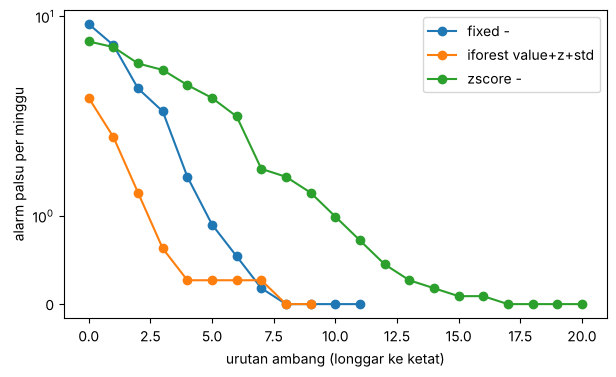

In [5]:
ev = rd(R2+"method_evaluation.csv"); a = ev[(ev.period == "all") & (ev.persistence == 3)]
fig, ax = plt.subplots(figsize=(7, 4))
for (m, fs), g in a.groupby(["method", "feature_set"]):
    if m != "iforest" or fs == "value+z+std":
        g = g.sort_values("threshold"); ax.plot(range(len(g)), g.fa_per_week, marker="o", label=f"{m} {fs}")
ax.set_yscale("symlog"); ax.set_xlabel("urutan ambang (longgar ke ketat)"); ax.set_ylabel("alarm palsu per minggu"); ax.legend(); plt.show()

## Q5. Apakah Isolation Forest lebih baik daripada rolling z-score dan ambang tetap?

In [6]:
b = rd(R2+"selection_best_per_method.csv")
print(b[["method","feature_set","threshold","persistence","events_detected_train","events_detected_test","fa_per_week_test","precision_test","events_detected_all","fa_per_week_all","lead_mean_h_all"]].round(2).to_string(index=False))

 method feature_set  threshold  persistence  events_detected_train  events_detected_test  fa_per_week_test  precision_test  events_detected_all  fa_per_week_all  lead_mean_h_all
  fixed           -      35.00            6                      2                     2              0.70            0.38                    4             0.45            13.31
iforest value+z+std       0.60            3                      2                     2              1.97            0.12                    4             1.26             0.10
 zscore           -       3.25            3                      2                     1              3.81            0.04                    3             3.06             1.83


## Q6. Fitur mana yang paling membantu (Isolation Forest)

In [7]:
print(rd(R2+"iforest_features.csv").to_string(index=False))
print(b[b.method == "iforest"][["feature_set","events_detected_test","fa_per_week_test","lead_mean_h_all"]].round(2).to_string(index=False))

  feature_set                                            kolom
        value                                            value
      value+z                                   value, z_score
  value+z+std                     value, z_score, roll_std_24h
value+z+slope                         value, z_score, slope_6h
  semua fitur value, z_score, roll_std_24h, slope_6h, dev_mean
feature_set  events_detected_test  fa_per_week_test  lead_mean_h_all
value+z+std                     2              1.97              0.1


## Q7. Ambang yang menangkap kejadian dengan alarm palsu di bawah batas

In [8]:
print(rd(R2+"selection_limits.csv").round(2).to_string(index=False))
print(rd(R2+"final_rule.csv").T.to_string(header=False))

 batas_fa_per_minggu  method feature_set  threshold  persistence  events_detected_train  fa_per_week_train  events_detected_test  fa_per_week_test  events_detected_all  fa_per_week_all  lead_mean_h_all
                 1.0   fixed           -      35.00            6                      2               0.00                     2              0.70                    4             0.45            13.31
                 1.0 iforest value+z+std       0.60            3                      2               0.00                     2              1.97                    4             1.26             0.10
                 1.0  zscore           -       7.00            1                      1               0.00                     1              0.00                    2             0.00            -0.33
                 2.0   fixed           -      35.00            6                      2               0.00                     2              0.70                    4             0.45        

## Q8. Berapa titik berturut-turut sebelum alarm dikirim (persistence)

In [9]:
p = rd(R2+"persistence.csv"); print(p[p.period == "all"].round(2).to_string(index=False))

 method feature_set  threshold  persistence period  events_detected  events_total  false_alarms  fa_per_week  lead_mean_h
  fixed           -      35.00            1    all                4             4             6         0.54        14.42
  fixed           -      35.00            3    all                4             4             6         0.54        14.02
  fixed           -      35.00            6    all                4             4             5         0.45        13.31
iforest value+z+std       0.60            1    all                3             4            20         1.80         8.14
iforest value+z+std       0.60            3    all                4             4            14         1.26         0.10
iforest value+z+std       0.60            6    all                3             4             8         0.72        14.94
 zscore           -       3.25            1    all                3             4            43         3.87         2.00
 zscore           -     

## Q9. Peringatan dini rata-rata dan minimum (jam)

In [10]:
print(rd(R2+"lead_time.csv").round(2).to_string(index=False))
e = rd(R2+"event_detail.csv"); print(e[e.method == "fixed"].round(2).to_string(index=False))
print(rd(R2+"margin_sensitivity.csv").round(2).to_string(index=False))

 method feature_set  events_total  events_detected  events_with_lead_ge_min  lead_mean_h  lead_median_h  lead_min_h  lead_max_h
  fixed           -             4                4                        3        13.31          15.54       -0.08       22.25
iforest value+z+std             4                4                        1         0.10           0.79      -22.92       21.75
 zscore           -             4                3                        2         1.83           5.33      -21.58       21.75
method feature_set  window_id        window_start          window_mid          window_end  detected         first_alarm  lead_h
 fixed           -          1 2013-12-10 06:25:00 2013-12-11 06:00:00 2013-12-12 05:35:00      True 2013-12-10 07:45:00   22.25
 fixed           -          2 2013-12-15 17:50:00 2013-12-16 17:25:00 2013-12-17 17:00:00      True 2013-12-16 06:45:00   10.67
 fixed           -          3 2014-01-27 14:20:00 2014-01-28 13:55:00 2014-01-29 13:30:00      True 2014

## Q10. Jam downtime yang bisa dicegah per tahun (estimated)

In [11]:
print(rd(R2+"impact.csv").round(2).to_string(index=False))

 downtime_per_kegagalan_h                 skenario  share_dengan_peringatan  kegagalan_per_tahun  jam_downtime_dicegah_per_tahun
                        4                    titik                     0.75                18.54                           55.61
                        4 batas bawah (Wilson 95%)                     0.30                18.54                           22.29
                        4  batas atas (Wilson 95%)                     0.95                18.54                           70.77
                        8                    titik                     0.75                18.54                          111.22
                        8 batas bawah (Wilson 95%)                     0.30                18.54                           44.58
                        8  batas atas (Wilson 95%)                     0.95                18.54                          141.54
                       12                    titik                     0.75                18.54 

## Q11. Apakah evaluasi bocor ke masa depan

In [12]:
print(rd(R2+"leakage_check.csv").to_string(index=False))

 method                        feature_set  ambang_data_lengkap  persistence_data_lengkap  ambang_hanya_data_latih  persistence_hanya_data_latih status ts_terakhir_data_latih
  fixed                                  -            35.000000                       6.0                35.000000                           6.0   PASS    2013-12-31 23:55:00
iforest                        semua fitur             0.631518                       3.0                 0.631518                           3.0   PASS    2013-12-31 23:55:00
iforest                              value             0.607500                       6.0                 0.607500                           6.0   PASS    2013-12-31 23:55:00
iforest                            value+z             0.646159                       3.0                 0.646159                           3.0   PASS    2013-12-31 23:55:00
iforest                      value+z+slope             0.619380                       1.0                 0.619380           

## Q12. Statistik bergulir SQL sama dengan pandas

In [13]:
print(rd(R2+"crosscheck_features.csv").to_string(index=False))
c = rd(R2+"crosscheck_alarms.csv"); print(c.status.value_counts().to_string())

                     fitur  titik_dibandingkan pola_kosong_sama  selisih_maks status
             roll_mean_24h               22407               ya  7.105427e-14   PASS
              roll_std_24h               22407               ya  8.276491e-12   PASS
                   z_score               22407               ya  3.157385e-11   PASS
                  dev_mean               22407               ya  7.105427e-14   PASS
                  slope_6h               22624               ya  1.326717e-14   PASS
     profil jam: rata-rata                  24               ya  8.526513e-14   PASS
profil jam: simpangan baku                  24               ya  2.309264e-14   PASS
status
PASS    996


## Aturan alarm usulan

# Aturan alarm usulan

**Aturan:** kirim alarm jika suhu menyimpang lebih dari **35 derajat** dari median data latih selama **6 titik berturut-turut** (30 menit). Satu episode ditutup setelah 1 jam tanpa alarm.

Ambang dan persistence dipilih dari data sebelum 2014-01-01 saja, dengan batas alarm palsu 2,0 per minggu (asumsi, belum disepakati dengan tim maintenance).

## Hasil
| Periode | Kejadian terdeteksi | Peringatan dini | Alarm palsu per minggu | Precision (episode) |
|---|---|---|---|---|
| Latih | 2 dari 2 | 2 | 0,00 | 1,00 |
| Uji | 2 dari 2 | 1 | 0,70 | 0,38 |
| Semua | 4 dari 4 | 3 | 0,45 | 0,50 |

## Lead time per kejadian (jam; negatif = setelah perkiraan waktu kegagalan)
| Jendela | Titik tengah (perkiraan kegagalan) | Alarm pertama | Lead time |
|---|---|---|---|
| 1 | 2013-12-11 06:00:00 | 2013-12-10 07:45:00 | 22,2 |
| 2 | 2013-12-16 17:25:00 | 2013-12-16 06:45:00 | 10,7 |
| 3 | 2014-01-28 13:55:00 | 2014-01-28 14:00:00 | -0,1 |
| 4 | 2014-02-08 14:30:00 | 2014-02-07 18:05:00 | 20,4 |



## Alasan dan batasan
- Aturan paling sederhana mengalahkan rolling z-score dan Isolation Forest pada data ini; lihat `results/2-analysis/selection_best_per_method.csv`.
- Hanya 4 kejadian (2 latih, 2 uji): kesimpulan bersifat indikatif, bukan bukti umum.
- "Alarm palsu" adalah alarm di luar jendela berlabel; sebagian bisa gangguan nyata yang tidak dilabeli NAB.
- Titik tengah jendela hanyalah pendekatan waktu kegagalan.


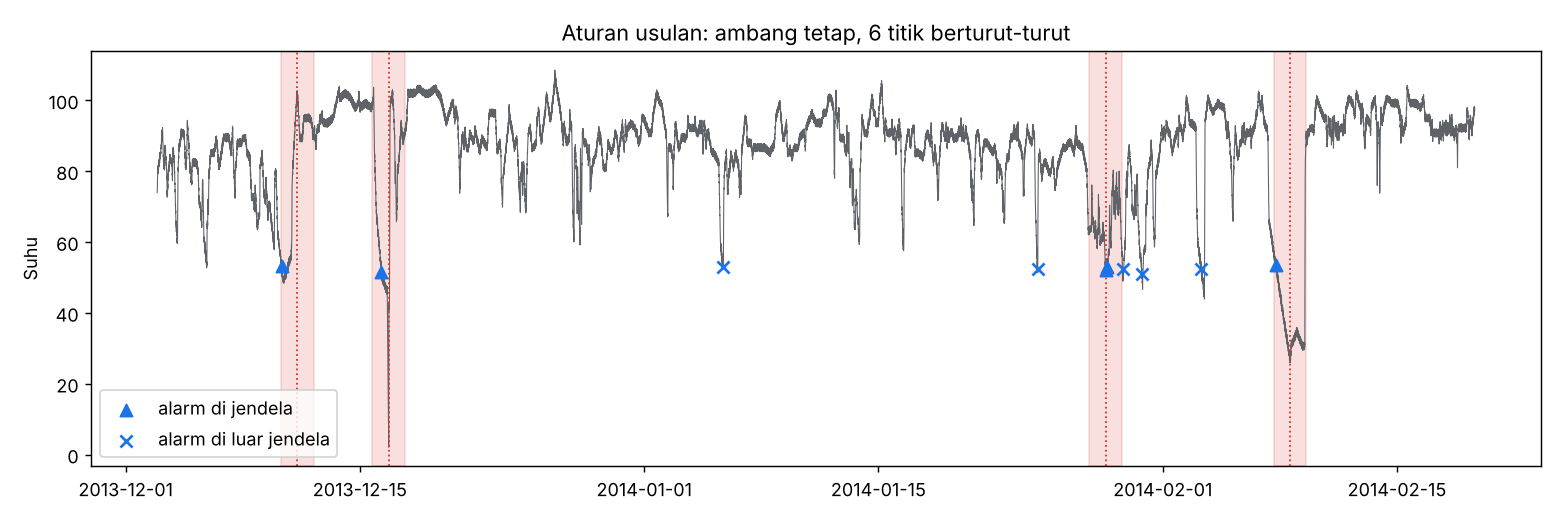

In [14]:
from IPython.display import Markdown, Image, display
display(Markdown(open(R3+"alarm_rule.md", encoding="utf-8").read().replace("![Aturan alarm](alarm_rule.png)", "")))
display(Image(R3+"alarm_rule.png"))